In [1]:
# Import modules
import numpy as np
import matplotlib.pyplot as plt
import numpy as np

In [2]:
lim1 = np.deg2rad(170)
lim2 = np.deg2rad(120)
lim3 = np.deg2rad(170)
lim4 = np.deg2rad(120)
lim5 = np.deg2rad(170)
lim6 = np.deg2rad(120)
lim7 = np.deg2rad(175)

constraints = (np.array([-lim1 , -lim2 , -lim3 , -lim4 , -lim5 , -lim6, -lim7]),
               np.array([ lim1  , lim2 ,  lim3 ,  lim4 ,  lim5 ,  lim6,  lim7]))

d2 = d4 = d4 = d6 = 0.01
d1 = 0.34
d3 = 0.4
d5 = 0.4
d7 = 0.126

In [3]:
def getTransformMatrix(theta, d, a, alpha):
    T = np.array([[np.cos(theta) , -np.sin(theta)*np.cos(alpha) ,  np.sin(theta)*np.sin(alpha) , a*np.cos(theta)],
                  [np.sin(theta) ,  np.cos(theta)*np.cos(alpha) , -np.cos(theta)*np.sin(alpha) , a*np.sin(theta)],
                  [0             ,  np.sin(alpha)               ,  np.cos(alpha)               , d              ],
                  [0             ,  0                           ,  0                           , 1              ]
                 ])
    return T

def get_end_tip_position(params):
    # Create the transformation matrices for the respective joints
    t_00 = np.array([[1,0,0,0],[0,1,0,0],[0,0,1,0],[0,0,0,1]])
    t_01 = getTransformMatrix(params[0] , d1  , 0 , -np.pi/2)
    t_12 = getTransformMatrix(params[1] , d2  , 0 ,  np.pi/2)
    t_23 = getTransformMatrix(params[2] , d3  , 0 ,  np.pi/2)
    t_34 = getTransformMatrix(params[3] , d4  , 0 , -np.pi/2)
    t_45 = getTransformMatrix(params[4] , d5  , 0 , -np.pi/2)
    t_56 = getTransformMatrix(params[5] , d6  , 0 ,  np.pi/2)
    t_67 = getTransformMatrix(params[6] , d7  , 0 ,        0)

    # Get the overall transformation matrix
    end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23).dot(t_34).dot(t_45).dot(t_56).dot(t_67)

    # The coordinates of the end tip are the 3 upper entries in the 4th column
    pos = np.array([end_tip_m[0,3],end_tip_m[1,3],end_tip_m[2,3]])
    return pos

def get_nth_position(params,n):
    # Create the transformation matrices for the respective joints
    t_00 = np.array([[1,0,0,0],[0,1,0,0],[0,0,1,0],[0,0,0,1]])
    t_01 = getTransformMatrix(params[0] , d1  , 0 , -np.pi/2)
    t_12 = getTransformMatrix(params[1] , d2  , 0 ,  np.pi/2)
    t_23 = getTransformMatrix(params[2] , d3  , 0 ,  np.pi/2)
    t_34 = getTransformMatrix(params[3] , d4  , 0 , -np.pi/2)
    t_45 = getTransformMatrix(params[4] , d5  , 0 , -np.pi/2)
    t_56 = getTransformMatrix(params[5] , d6  , 0 ,  np.pi/2)
    t_67 = getTransformMatrix(params[6] , d7  , 0 ,        0)

    if n==0:
        end_tip_m = t_00#.dot(t_01).dot(t_12).dot(t_23).dot(t_34).dot(t_45).dot(t_56).dot(t_67)
    elif n==1:
        end_tip_m = t_00.dot(t_01)#.dot(t_12).dot(t_23).dot(t_34).dot(t_45).dot(t_56).dot(t_67)
    elif n==2:
        end_tip_m = t_00.dot(t_01).dot(t_12)#.dot(t_23).dot(t_34).dot(t_45).dot(t_56).dot(t_67)
    elif n==3:
        end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23)#.dot(t_34).dot(t_45).dot(t_56).dot(t_67)
    elif n==4:
        end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23).dot(t_34)#.dot(t_45).dot(t_56).dot(t_67)
    elif n==5:
        end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23).dot(t_34).dot(t_45)#.dot(t_56).dot(t_67)
    elif n==6:
        end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23).dot(t_34).dot(t_45).dot(t_56)#.dot(t_67)
    elif n==7:
        end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23).dot(t_34).dot(t_45).dot(t_56).dot(t_67)
    else:
        print('no more tf')
        
    # The coordinates of the end tip are the 3 upper entries in the 4th column
    pos = np.array([end_tip_m[0,3],end_tip_m[1,3],end_tip_m[2,3]])
    return pos

# Plot the resulting joint configuration and end pose.
def visualize_config(sol, target, alg):
    fig = plt.figure(figsize=(8, 8))
    ax = fig.add_subplot(projection='3d')
    for i in range(7):
        point = get_nth_position(sol,i)
        point_n = get_nth_position(sol,i+1)
        print(f"{i}: {point}")
        x,y,z = [point[0],point_n[0]], [point[1],point_n[1]], [point[2],point_n[2]]
        ax.scatter(x, y, z, c='red', s=100)
        ax.plot(x, y, z, color='black',linewidth=4)
        if i==6:
            ax.scatter(point_n[0], point_n[1], point_n[2], c='red', s=120)

    ax.scatter(0,0,0)
    ax.scatter(target[0],target[1],target[2],c='green', s=260)

    fig.suptitle('Arm Visualization via {}'.format(alg))
    ax.set_xlabel('X Label')
    ax.set_ylabel('Y Label', fontsize=10)
    ax.set_zlabel('Z Label', fontsize=10)
    plt.show()

### Genetic Algorithm

In [4]:
def initialize_population(population_size, constraints):
    population = []
    for _ in range(population_size):
        individual = [np.random.uniform(low, high) for low, high in zip(constraints[0], constraints[1])]
        population.append(individual)
    return np.array(population)

def fitness_function(solution, target_position):
    #n_particles = solution.shape[0]  # number of particles
    #n_particles = len(solution)  # number of particles

    # Calculate the forward kinematics of the solution(joint angles).
    current_position = get_end_tip_position(solution)
    #current_position = [get_end_tip_position(solution) for i in range(n_particles)]

    # Calculate the distance between the current and target positions.
    position_distance = np.linalg.norm(target_position - current_position)
    # The fitness could be the inverse of the error (since we want to minimize the error).
    fitness = 1 / (1 + position_distance)
    return fitness

def select_parents(population, fitness_scores, num_parents):
    parents = np.zeros((num_parents, population.shape[1]))
    for i in range(num_parents):
        max_fitness_idx = np.where(fitness_scores == np.max(fitness_scores))
        parents[i, :] = population[max_fitness_idx[0][0], :]
        fitness_scores[max_fitness_idx[0][0]] = -99999999999  # Exclude this parent from being selected again
    return parents

def crossover(parents, offspring_size):
    offspring = np.zeros(offspring_size)
    crossover_point = np.uint8(offspring_size[1]/2)
    for k in range(offspring_size[0]):
        # Index of the first parent to mate.
        parent1_idx = k % parents.shape[0]
        # Index of the second parent to mate.
        parent2_idx = (k + 1) % parents.shape[0]
        # The new offspring will have half of its genes from each parent.
        offspring[k, 0:crossover_point] = parents[parent1_idx, 0:crossover_point]
        offspring[k, crossover_point:] = parents[parent2_idx, crossover_point:]
    return offspring

def mutation(offspring_crossover, mutation_rate, joint_limits):
    for idx in range(offspring_crossover.shape[0]):
        for jdx in range(offspring_crossover.shape[1]):
            if np.random.rand() < mutation_rate:
                # Randomly change the jdx gene of the idx offspring.
                random_value = np.random.uniform(joint_limits[0][jdx], joint_limits[1][jdx])
                offspring_crossover[idx, jdx] = random_value
    return offspring_crossover

def optimize_ga():
    population = initialize_population(population_size, constraints)
    for generation in range(num_generations):
        # Evaluate fitness
        fitness_scores = np.array([fitness_function(individual, target_position) for individual in population])
        # Select parents
        parents = select_parents(population, fitness_scores, num_parents=population_size//2)
        # Crossover
        offspring_crossover = crossover(parents, offspring_size=(population_size - parents.shape[0], 7))
        # Mutation
        offspring_mutation = mutation(offspring_crossover, mutation_rate=0.1, joint_limits=constraints)
        # Create new population
        population[0:parents.shape[0], :] = parents
        population[parents.shape[0]:, :] = offspring_mutation
        # Check for convergence or other termination criteria
        # (not shown here; could be based on fitness threshold, etc.)

    # Best solution
    best_idx = np.argmax(fitness_scores)
    best_solution = population[best_idx, :]
    return best_idx, best_solution
    


## Optimize With Genetic Algorithm (GA)

Target position: [-0.35941168  0.31812675 -0.10937107]
Best solution: [-0.32064861 -1.58252601 -0.2776926   1.6511709  -2.42984546 -0.96754822
 -0.06422455]

0: [0 0 0]
1: [0.   0.   0.34]
2: [0.00315182 0.00949031 0.34      ]
3: [-0.37643454  0.13555451  0.33530824]
4: [-0.3794351   0.12641763  0.33256705]
5: [-0.31024091  0.21860867 -0.05046425]
6: [-0.31864031  0.21387645 -0.05312058]


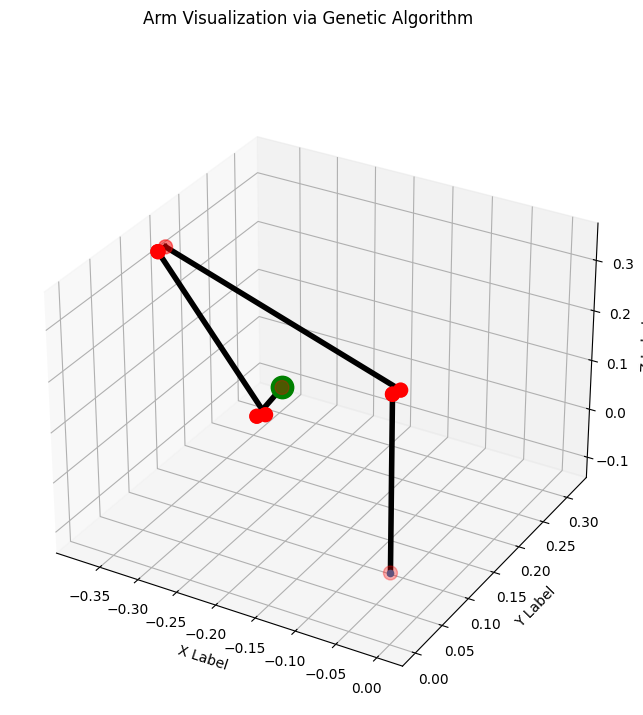

In [5]:
population_size = 80
num_generations = 1200

# Target position and orientation     #target_position = np.array([-0.2, 0.4, 1.2])
# Workspace range
x, y, z = np.random.uniform(-0.4,0.4), np.random.uniform(-0.4,0.4), np.random.uniform(-0.15,0.9)
target_position = np.array([x,y,z])

# Calculate the joint configuration
best_idx, best_solution = optimize_ga()
    
print(f"Target position: {target_position}")
print(f"Best solution: {best_solution}\n")
visualize_config(best_solution, target_position, 'Genetic Algorithm')